In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay


In [2]:
PATH = "../../statsbomb_pipeline/data/processed/player_season_model_dataset.csv"

pre_df = pd.read_csv(PATH)

# Filter to players with enough minutes (same rule as PCA)
MIN_MINUTES = 900
df = pre_df[pre_df["minutes_played_total"] >= MIN_MINUTES].copy()
df.head()
df[['xg_total']].describe()


,xg_total
count,324.000000
mean,2.691860
std,3.404107
min,0.000000
25%,0.642783
50%,1.565982
75%,3.205529
max,22.298685


In [5]:
def categorize_xg(x):
    if x < 1.5: 
        return "low"
    elif x < 3.2: 
        return "medium"
    else:
        return "high"
    

df["xg_class"] = df["xg_total"].apply(categorize_xg)
df["xg_class"].value_counts()



xg_class
low       157
medium     85
high       82
Name: count, dtype: int64

In [6]:
feature_cols = [
    "minutes_played_total",
    "matches_played",
    "xThreat_total",
    "xThreat_pass_total",
    "xThreat_carry_total",
    "xThreat_per90",
    "xThreat_pass_per90",
    "xThreat_carry_per90",
]

# Drop any rows with missing values in these columns or target
model_df = df.dropna(subset=feature_cols + ['xg_class']).copy()

X = model_df[feature_cols]
y = model_df['xg_class']

X.shape, y.shape


((324, 8), (324,))

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape


((259, 8), (65, 8))

KNN accuracy: 0.47692307692307695

KNN classification report:

              precision    recall  f1-score   support

        high       0.38      0.31      0.34        16
         low       0.59      0.81      0.68        32
      medium       0.00      0.00      0.00        17

    accuracy                           0.48        65
   macro avg       0.33      0.38      0.34        65
weighted avg       0.39      0.48      0.42        65



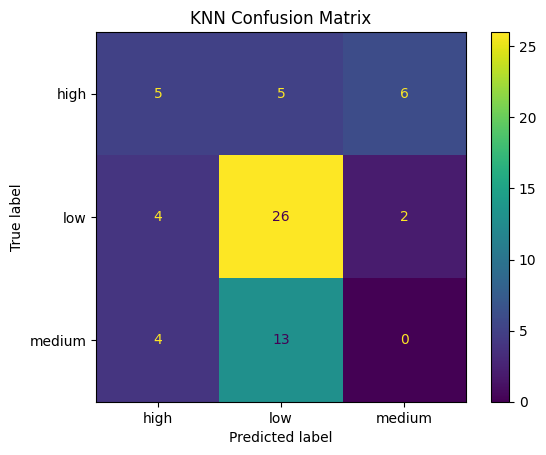

[(1, 0.4461538461538462),
 (3, 0.49230769230769234),
 (5, 0.5384615384615384),
 (7, 0.47692307692307695),
 (9, 0.5384615384615384),
 (11, 0.49230769230769234),
 (13, 0.49230769230769234),
 (15, 0.49230769230769234)]

In [8]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=7))
])

knn_pipeline.fit(X_train, y_train)
y_pred_knn = knn_pipeline.predict(X_test)

print("KNN accuracy:", accuracy_score(y_test, y_pred_knn))
print("\nKNN classification report:\n")
print(classification_report(y_test, y_pred_knn))

ConfusionMatrixDisplay.from_estimator(knn_pipeline, X_test, y_test)
plt.title("KNN Confusion Matrix")
plt.show()


## Manual Hyperparameter search for K

k_values = range(1, 16, 2)
knn_results = []

for k in k_values:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])
    pipe.fit(X_train, y_train)
    y_val = pipe.predict(X_test)
    acc = accuracy_score(y_test, y_val)
    knn_results.append((k, acc))

knn_results


Decision Tree accuracy: 0.49230769230769234

Decision Tree classification report:

              precision    recall  f1-score   support

        high       0.37      0.44      0.40        16
         low       0.54      0.78      0.64        32
      medium       0.00      0.00      0.00        17

    accuracy                           0.49        65
   macro avg       0.30      0.41      0.35        65
weighted avg       0.36      0.49      0.41        65



/home/mauposad/miniforge3/envs/data-mining/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/mauposad/miniforge3/envs/data-mining/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/mauposad/miniforge3/envs/data-mining/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

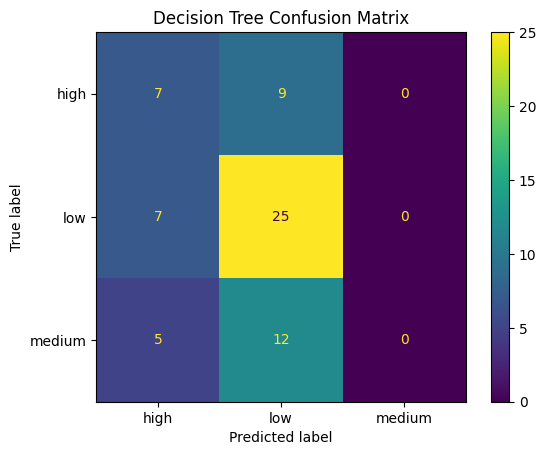

In [9]:
dt = DecisionTreeClassifier(
    max_depth=5,        # keep it from overfitting too hard
    min_samples_leaf=20,
    random_state=42
)

dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print("Decision Tree accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nDecision Tree classification report:\n")
print(classification_report(y_test, y_pred_dt))

ConfusionMatrixDisplay.from_estimator(dt, X_test, y_test)
plt.title("Decision Tree Confusion Matrix")
plt.show()
